# 01 · Data exploration — SciFact
**Owner:** Laiba Shaikh (data handling) · **Goal:** understand the corpus and the claim/evidence annotations *before* choosing preprocessing and metrics.

SciFact = a corpus of 5,183 scientific abstracts + expert-written claims, each labelled with the abstracts that **SUPPORT** or **CONTRADICT** it
(plus *NOT_ENOUGH_INFO* claims that have no evidence). For retrieval, a document is *relevant* to a claim iff it holds annotated evidence for it.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))          # so `import retrieval` works from notebooks/
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from retrieval.data import load_corpus, load_claims, build_qrels
FIG = ROOT / "results" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

## 1 · The corpus

In [2]:
corpus = load_corpus()
df = pd.DataFrame(corpus)
df["n_words"] = df["abstract"].str.split().str.len()
df["n_sents"] = df["sentences"].str.len()
print("documents:", len(df), "| unique ids:", df["id"].nunique())
print("empty titles:", (df["title"] == "").sum(), "| empty abstracts:", (df["abstract"] == "").sum())
print(df[["n_words", "n_sents"]].describe().round(1).to_string())

documents: 5183 | unique ids: 5183
empty titles: 0 | empty abstracts: 0
       n_words  n_sents
count   5183.0   5183.0
mean     201.8      8.9
std       86.0      8.0
min       26.0      3.0
25%      147.0      6.0
50%      192.0      8.0
75%      247.0     11.0
max     1524.0    367.0


share of abstracts > 200 words: 0.441 | > 350 words: 0.043


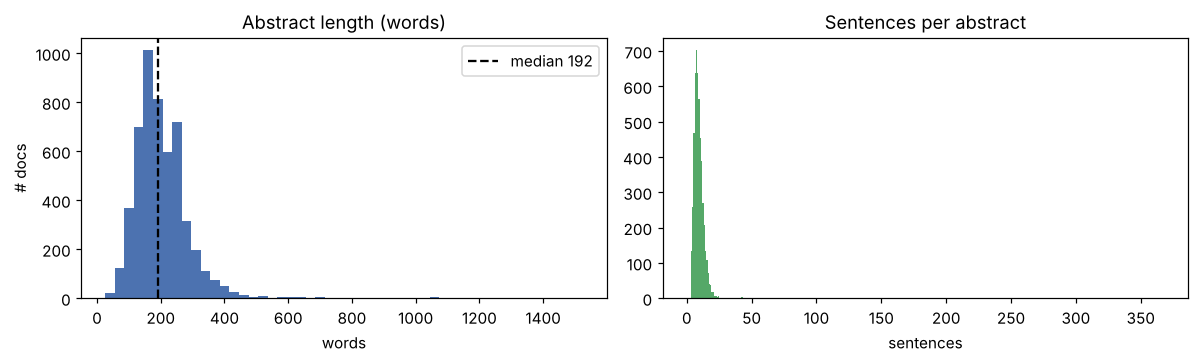

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(df["n_words"], bins=50, color="#4C72B0"); ax[0].axvline(df["n_words"].median(), color="k", ls="--", label=f"median {df['n_words'].median():.0f}")
ax[0].set(title="Abstract length (words)", xlabel="words", ylabel="# docs"); ax[0].legend()
ax[1].hist(df["n_sents"], bins=range(0, int(df["n_sents"].max()) + 2), color="#55A868")
ax[1].set(title="Sentences per abstract", xlabel="sentences")
plt.tight_layout(); plt.savefig(FIG / "01_doc_lengths.png", dpi=130); plt.show()
print("share of abstracts > 200 words:", round((df["n_words"] > 200).mean(), 3),
      "| > 350 words:", round((df["n_words"] > 350).mean(), 3))

**Takeaway:** the median abstract is ~190 words. MiniLM's input limit is 256 *tokens* (word-pieces, which outnumber words), so a meaningful share of abstracts — at least the ~27% that exceed 256 words — will be truncated by that model. This motivates the `max_seq_length` ablation in notebook 04.

## 2 · Claims and annotations

In [4]:
def claim_label(c):
    labs = {v["label"] for ev in c.get("evidence", {}).values() for v in ev}
    if not c.get("evidence"): return "NOT_ENOUGH_INFO / no evidence"
    return "SUPPORT" if labs == {"SUPPORT"} else "CONTRADICT" if labs == {"CONTRADICT"} else "MIXED"

rows = []
splits = {s: load_claims(s) for s in ["train", "dev", "test"]}
for s, cl in splits.items():
    labelled = "labels" if s != "test" else "no labels (hidden)"
    cnt = Counter(claim_label(c) for c in cl) if s != "test" else {}
    rows.append({"split": s, "claims": len(cl), "scorable for retrieval": len(build_qrels(cl)),
                 "SUPPORT": cnt.get("SUPPORT", "-"), "CONTRADICT": cnt.get("CONTRADICT", "-"),
                 "MIXED": cnt.get("MIXED", "-"), "NEI": cnt.get("NOT_ENOUGH_INFO / no evidence", "-"), "labels": labelled})
print(pd.DataFrame(rows).to_string(index=False))

split  claims  scorable for retrieval SUPPORT CONTRADICT MIXED NEI             labels
train     809                     505     332        173     - 304             labels
  dev     300                     188     124         64     - 112             labels
 test     300                       0       -          -     -   - no labels (hidden)


**Important consequences for the project**
* The **test** claims are unlabeled (standard SciFact practice), so they can only be used for the live demo, **not** for scoring.
* We therefore **tune on train** (505 scorable claims) and **report on dev** (188 scorable claims). Dev is never used for tuning.
* NEI claims have no relevant document → excluded from retrieval metrics (they matter later for the RAG answer-quality evaluation: the LLM should say "not enough evidence").

In [5]:
tr, dv = splits["train"], splits["dev"]
qr = build_qrels(tr)
n_rel = Counter(len(v) for v in qr.values())
print("relevant docs per scorable train claim:", dict(sorted(n_rel.items())))
ev_sents = [len(v["sentences"]) for c in tr for ev in c.get("evidence", {}).values() for v in ev]
print("evidence sentences per rationale: mean", round(np.mean(ev_sents), 2), "max", max(ev_sents))
claim_len = pd.Series([len(c["claim"].split()) for c in tr + dv + splits["test"]])
print("claim length (words):", claim_len.describe().round(1).to_dict())

all_rel = Counter(d for q in qr.values() for d in q)
print("docs that are relevant to >1 train claim:", sum(1 for v in all_rel.values() if v > 1), "of", len(all_rel))

relevant docs per scorable train claim: {1: 468, 2: 20, 3: 12, 4: 5}
evidence sentences per rationale: mean 1.07 max 4
claim length (words): {'count': 1409.0, 'mean': 12.3, 'std': 4.7, 'min': 3.0, '25%': 9.0, '50%': 12.0, '75%': 15.0, 'max': 39.0}
docs that are relevant to >1 train claim: 143 of 365


In [6]:
c = next(c for c in dv if c.get("evidence"))
doc_id = next(iter(c["evidence"]))
d = next(d for d in corpus if d["id"] == doc_id)
print("CLAIM :", c["claim"])
for ev in c["evidence"][doc_id]:
    print("LABEL :", ev["label"])
    for i in ev["sentences"]:
        print("  evidence sentence:", d["sentences"][i])
print("DOC   :", d["title"])

CLAIM : 1,000 genomes project enables mapping of genetic sequence variation consisting of rare variants with larger penetrance effects than common variants.
LABEL : SUPPORT
  evidence sentence: We propose as an alternative explanation that variants much less common than the associated one may create "synthetic associations" by occurring, stochastically, more often in association with one of the alleles at the common site versus the other allele.
  evidence sentence: We show that they are not only possible, but inevitable, and that under simple but reasonable genetic models, they are likely to account for or contribute to many of the recently identified signals reported in genome-wide association studies.
LABEL : SUPPORT
  evidence sentence: In conclusion, uncommon or rare genetic variants can easily create synthetic associations that are credited to common variants, and this possibility requires careful consideration in the interpretation and follow up of GWAS signals.
DOC   : Rare Var

## 3 · What this means for the design
| Finding | Decision |
|---|---|
| ~1.1 relevant docs per claim (almost always 1) | Use rank-aware metrics: **Recall@k, MRR@10, nDCG@10, MAP**; Hit@k is nearly equal to Recall@k here |
| Median abstract ≈ 190 words | Index `title + abstract` as one text; watch truncation for 256-token models |
| Test labels hidden | Tune on train, report on dev, demo on test |
| Claims are short, declarative sentences (~12 words) | Dense models see a *sentence-vs-paragraph* match; BGE's query instruction prefix is worth testing |